In [1]:
import numpy as np
import pandas as pd
import random

np.random.seed(42)
random.seed(42)

n = 6000
stores = ["万象城店", "裕华店", "长安店", "新华店"]
categories = ["跑步鞋", "篮球鞋", "外套", "短裤", "背包"]
members = ["普通", "银卡", "金卡"]

data = {
    "store": np.random.choice(stores, n),
    "category": np.random.choice(categories, n),
    "member": np.random.choice(members, n),
    "price": np.random.randint(99, 899, n),
    "quantity": np.random.randint(1, 5, n),
}
df = pd.DataFrame(data)

# 制造脏数据
df.loc[np.random.choice(df.index, 80), "price"] = np.nan
df.loc[np.random.choice(df.index, 120), "store"] = ""
dup = df.sample(200)
df = pd.concat([df, dup], ignore_index=True)

df.to_csv("sales_data.csv", index=False, encoding="utf-8-sig")
print("✅ 数据集 sales_data.csv 生成完成！")

✅ 数据集 sales_data.csv 生成完成！


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 设置中文
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# 读取数据
df = pd.read_csv(r"E:\ai-learning\sales_data.csv", encoding="utf-8-sig")

print("=== 数据集形状 ===")
print(df.shape)
print("\n=== 前 5 行 ===")
print(df.head())
print("\n=== 基础信息 ===")
print(df.info())
print("\n=== 缺失值统计 ===")
print(df.isnull().sum())
print("\n=== 重复行数量 ===")
print("重复行数：", df.duplicated().sum())

=== 数据集形状 ===
(6200, 5)

=== 前 5 行 ===
  store category member  price  quantity
0   长安店       外套     银卡  777.0         1
1   新华店      跑步鞋     银卡  764.0         2
2  万象城店       背包     金卡  617.0         3
3   长安店       外套     普通  295.0         4
4   长安店      篮球鞋     金卡  144.0         2

=== 基础信息 ===
<class 'pandas.DataFrame'>
RangeIndex: 6200 entries, 0 to 6199
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   store     6078 non-null   str    
 1   category  6200 non-null   str    
 2   member    6200 non-null   str    
 3   price     6115 non-null   float64
 4   quantity  6200 non-null   int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 381.2 KB
None

=== 缺失值统计 ===
store       122
category      0
member        0
price        85
quantity      0
dtype: int64

=== 重复行数量 ===
重复行数： 296


In [ ]:
# 删除重复行
df = df.drop_duplicates()
print("去重之后行数：", df.shape[0])

In [ ]:
# 剔除 store 为空
df = df[df["store"] != ""]
print("剔除空门店之后行数：", df.shape[0])

In [ ]:
# 删除 price 缺失
df = df.dropna(subset=["price"])
print("删除价格缺失之后行数：", df.shape[0])

In [ ]:
df["amount"] = df["price"] * df["quantity"]
print(df.head())

In [2]:
print("=== 清洗完毕 ===")
print(df.shape)
print("\n缺失值统计：")
print(df.isnull().sum())
print("\n重复行：", df.duplicated().sum())

=== 清洗完毕 ===
(6200, 5)

缺失值统计：
store       122
category      0
member        0
price        85
quantity      0
dtype: int64

重复行： 296


In [3]:
df = df.drop_duplicates()
print("去重之后行数：", df.shape[0])

去重之后行数： 5904


In [4]:
df = df[df["store"] != ""]
print("剔除空门店之后行数：", df.shape[0])

剔除空门店之后行数： 5904


In [5]:
df = df.dropna(subset=["price"])
print("删除价格缺失之后行数：", df.shape[0])

删除价格缺失之后行数： 5833


In [6]:
df["amount"] = df["price"] * df["quantity"]
print(df.head())

  store category member  price  quantity  amount
0   长安店       外套     银卡  777.0         1   777.0
1   新华店      跑步鞋     银卡  764.0         2  1528.0
2  万象城店       背包     金卡  617.0         3  1851.0
3   长安店       外套     普通  295.0         4  1180.0
4   长安店      篮球鞋     金卡  144.0         2   288.0


In [7]:
print("=== 清洗完毕 ===")
print(df.shape)
print("\n缺失值统计：")
print(df.isnull().sum())
print("\n重复行：", df.duplicated().sum())

=== 清洗完毕 ===
(5833, 6)

缺失值统计：
store       117
category      0
member        0
price         0
quantity      0
amount        0
dtype: int64

重复行： 0


In [8]:
# 把 store 先去掉首尾空格
df["store"] = df["store"].str.strip()
# 再过滤
df = df[df["store"] != ""]

print("再次清理门店后：", df.shape)
print(df.isnull().sum())
print("重复行：", df.duplicated().sum())

再次清理门店后： (5833, 6)
store       117
category      0
member        0
price         0
quantity      0
amount        0
dtype: int64
重复行： 0


In [9]:
# 各个门店的总销售额
store_sale = df.groupby("store")["amount"].sum()
print("各门店总营收：")
print(store_sale)

# 各个品类总销售额
cat_sale = df.groupby("category")["amount"].sum()
print("\n各品类总营收：")
print(cat_sale)

# 不同会员总销售额
mem_sale = df.groupby("member")["amount"].sum()
print("\n各会员总营收：")
print(mem_sale)

各门店总营收：
store
万象城店    1896291.0
新华店     1756728.0
裕华店     1779884.0
长安店     1731043.0
Name: amount, dtype: float64

各品类总营收：
category
外套     1478140.0
短裤     1383996.0
篮球鞋    1513666.0
背包     1430075.0
跑步鞋    1514220.0
Name: amount, dtype: float64

各会员总营收：
member
普通    2349458.0
金卡    2446428.0
银卡    2524211.0
Name: amount, dtype: float64


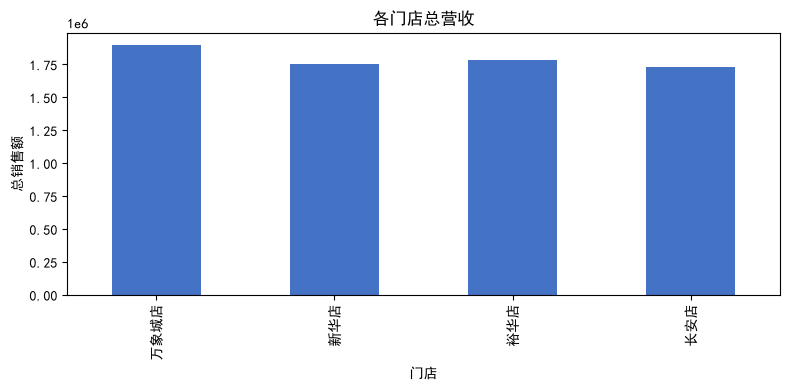

In [10]:
plt.figure(figsize=(8, 4))
store_sale.plot(kind="bar", color="#4472C4")
plt.title("各门店总营收")
plt.ylabel("总销售额")
plt.xlabel("门店")
plt.tight_layout()
plt.show()

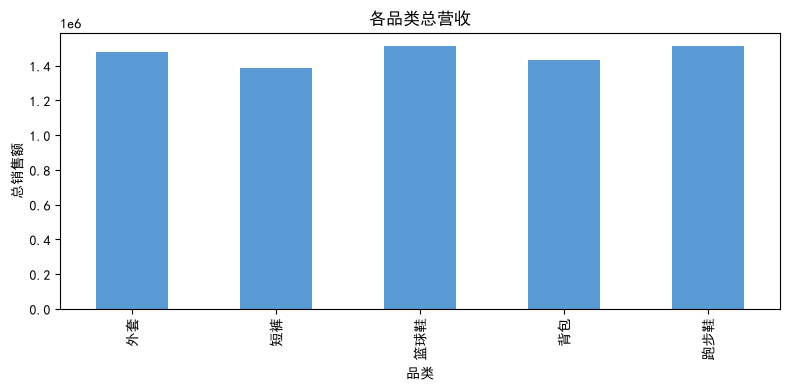

In [11]:
plt.figure(figsize=(8, 4))
cat_sale.plot(kind="bar", color="#5B9BD5")
plt.title("各品类总营收")
plt.ylabel("总销售额")
plt.xlabel("品类")
plt.tight_layout()
plt.show()

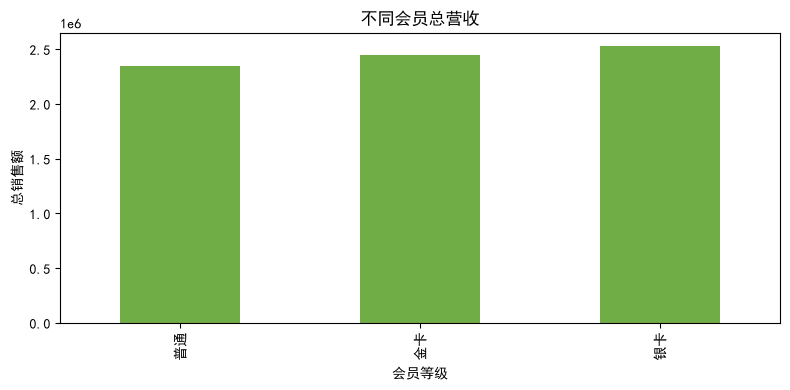

In [12]:
plt.figure(figsize=(8, 4))
mem_sale.plot(kind="bar", color="#70AD47")
plt.title("不同会员总营收")
plt.ylabel("总销售额")
plt.xlabel("会员等级")
plt.tight_layout()
plt.show()

In [13]:
pivot = df.pivot_table(index="store", columns="member", values="amount", aggfunc="sum")
print("门店 × 会员 营收透视表")
print(pivot)

门店 × 会员 营收透视表
member        普通        金卡        银卡
store                               
万象城店    613836.0  604589.0  677866.0
新华店     541544.0  614074.0  601110.0
裕华店     560855.0  571168.0  647861.0
长安店     591629.0  594930.0  544484.0
